# Chapitre 2 - Lab : tables, JSONB et requêtes récursives dans PostgreSQL

Ce lab confronte le cours à une vraie base relationnelle qui sait aussi stocker des
documents : PostgreSQL 16 et son type **JSONB** (JSON stocké sous forme binaire
décomposée, indexable). Nous allons :

1. ranger les mêmes CV en tables normalisées et en documents JSONB, et comparer leur
   taille ;
2. lire un profil complet : plusieurs requêtes, une jointure, un document, un agrégat
   JSON calculé par le serveur ;
3. indexer des valeurs **imbriquées** dans les documents (index GIN) pour interroger une
   relation plusieurs-à-plusieurs dans les deux sens ;
4. mesurer le prix de la localité : une petite modification dans un gros document,
   comptée en octets de journal (WAL) ;
5. migrer un schéma : ce qui est instantané et ce qui réécrit la table ;
6. stocker un graphe dans deux tables et l'interroger avec `WITH RECURSIVE`, y compris
   la détection de cycles.

**Démarrer et arrêter les services** (depuis la racine du dépôt) :

```bash
docker compose -f docker/datamodels/compose.yml -p ddia_datamodels up -d     # démarrer
docker compose -f docker/datamodels/compose.yml -p ddia_datamodels down -v   # arrêter et effacer
```

PostgreSQL écoute sur le port **10332** de la machine (utilisateur, mot de passe et base :
`ddia` / `ddia` / `modeles`).

In [1]:
import json
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import psycopg
from psycopg.types.json import Jsonb

from ddia import datamodels as dm
from ddia.diagrams import Diagram
from ddia.plotting import (AMBER, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET, COLORS,
                           annotate_bars, finish, set_style, subtitle)

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 3)
pd.set_option("display.max_colwidth", 120)
fmt = lambda v: f"{v:,.0f}".replace(",", " ")

DSN = "host=localhost port=10332 user=ddia password=ddia dbname=modeles"
con = None
for essai in range(30):
    try:
        con = psycopg.connect(DSN, autocommit=True)
        break
    except psycopg.OperationalError:
        time.sleep(1)
assert con is not None, "PostgreSQL ne répond pas : avez-vous lancé docker compose up ?"
print(con.execute("SELECT version()").fetchone()[0][:60])


def q(sql, params=None):
    return con.execute(sql, params).fetchall()


def plan(sql, params=None):
    return "\n".join(r[0] for r in q("EXPLAIN (ANALYZE, BUFFERS, TIMING OFF, SUMMARY OFF) " + sql, params))


def wal_bytes(fn):
    """Octets de journal (WAL) écrits pendant fn()."""
    a = q("SELECT pg_current_wal_lsn()")[0][0]
    fn()
    b = q("SELECT pg_current_wal_lsn()")[0][0]
    return float(q("SELECT pg_wal_lsn_diff(%s, %s)", (b, a))[0][0])

PostgreSQL 16.14 (Debian 16.14-1.pgdg13+1) on x86_64-pc-linu


## 1. Les mêmes CV en tables et en documents (section *The Object-Relational Mismatch*)

On génère 50 000 profils synthétiques (`dm.make_profiles`) et on les range deux fois :
dans le schéma normalisé du cours 1 (cinq tables), et dans une table `profiles` à une
colonne `doc JSONB`.

In [2]:
orgs = dm.make_orgs(200, seed=0)
profiles = dm.make_profiles(50_000, seed=0, orgs=orgs)
con.execute("""
DROP TABLE IF EXISTS positions, education, contact_info, users, organizations, regions, profiles CASCADE;
CREATE TABLE regions (id text PRIMARY KEY, name text);
CREATE TABLE organizations (id int PRIMARY KEY, name text, logo_url text);
CREATE TABLE users (id int PRIMARY KEY, first_name text, last_name text, headline text,
                    region_id text REFERENCES regions, photo_url text);
CREATE TABLE positions (id serial PRIMARY KEY, user_id int REFERENCES users, job_title text,
                        org_id int REFERENCES organizations, start_year int, end_year int);
CREATE TABLE education (id serial PRIMARY KEY, user_id int REFERENCES users, school_name text,
                        start_year int, end_year int);
CREATE TABLE contact_info (user_id int REFERENCES users, kind text, value text);
CREATE TABLE profiles (user_id int PRIMARY KEY, doc jsonb);
""")
with con.cursor() as cur:
    with cur.copy("COPY regions FROM STDIN") as cp:
        for k, v in dm.REGIONS.items():
            cp.write_row((k, v))
    with cur.copy("COPY organizations FROM STDIN") as cp:
        for o in orgs:
            cp.write_row((o["org_id"], o["name"], o["logo_url"]))
    with cur.copy("COPY users FROM STDIN") as cp:
        for p in profiles:
            cp.write_row((p["user_id"], p["first_name"], p["last_name"], p["headline"], p["region_id"], p["photo_url"]))
    with cur.copy("COPY positions (user_id, job_title, org_id, start_year, end_year) FROM STDIN") as cp:
        for p in profiles:
            for x in p["positions"]:
                cp.write_row((p["user_id"], x["job_title"], x["org_id"], x["start"], x["end"]))
    with cur.copy("COPY education (user_id, school_name, start_year, end_year) FROM STDIN") as cp:
        for p in profiles:
            for x in p["education"]:
                cp.write_row((p["user_id"], x["school_name"], x["start"], x["end"]))
    with cur.copy("COPY contact_info FROM STDIN") as cp:
        for p in profiles:
            for k, v in p["contact_info"].items():
                cp.write_row((p["user_id"], k, v))
    with cur.copy("COPY profiles FROM STDIN") as cp:
        for p in profiles:
            cp.write_row((p["user_id"], json.dumps(p, ensure_ascii=False)))
con.execute("""
CREATE INDEX positions_user ON positions (user_id);
CREATE INDEX education_user ON education (user_id);
CREATE INDEX contact_user ON contact_info (user_id);
""")
con.execute("VACUUM ANALYZE")
tailles = pd.DataFrame(q("""
SELECT relname, (xpath('/row/c/text()', query_to_xml('SELECT count(*) AS c FROM ' || relname, false, true, '')))[1]::text::int,
       pg_size_pretty(pg_table_size(relid)) AS donnees,
       pg_size_pretty(pg_indexes_size(relid)) AS index, pg_total_relation_size(relid) AS total
  FROM pg_stat_user_tables WHERE relname IN ('users','positions','education','contact_info','profiles')
 ORDER BY relname"""), columns=["table", "lignes", "données", "index", "total (octets)"])
tailles

,table,lignes,données,index,total (octets)
0,contact_info,75330,5376 kB,1392 kB,6930432
1,education,74770,5224 kB,3040 kB,8462336
2,positions,175210,12 MB,6232 kB,18546688
3,profiles,50000,48 MB,1112 kB,51191808
4,users,50000,4968 kB,1112 kB,6225920


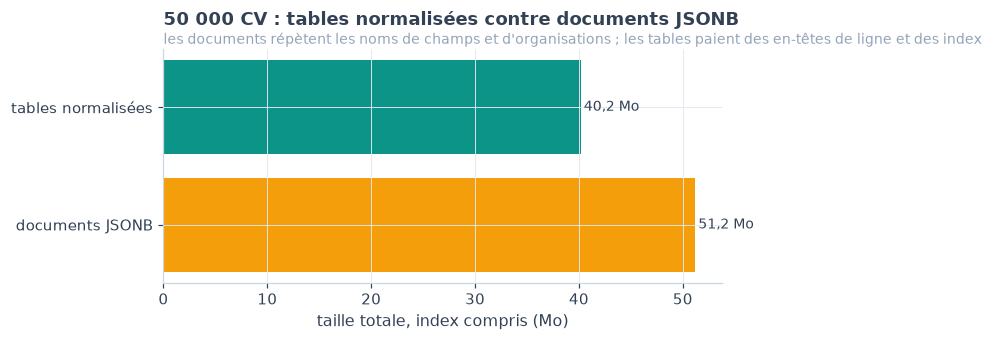

In [3]:
norm = tailles[tailles.table != "profiles"]["total (octets)"].sum()
docs = tailles[tailles.table == "profiles"]["total (octets)"].sum()
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.barh(["documents JSONB", "tables normalisées"], [docs / 1e6, norm / 1e6], color=[AMBER, TEAL])
for i, v in enumerate([docs, norm]):
    ax.text(v / 1e6 + 0.3, i, f"{v / 1e6:.1f} Mo".replace(".", ","), va="center", fontsize=9)
ax.set_xlabel("taille totale, index compris (Mo)")
ax.set_title("50 000 CV : tables normalisées contre documents JSONB")
subtitle(ax, "les documents répètent les noms de champs et d'organisations ; les tables paient des en-têtes de ligne et des index")
plt.tight_layout(); plt.show()

Les deux représentations ont des tailles du même ordre (les documents un peu plus
gros) : les documents répètent dans
chaque profil les **noms de champs** et le nom des organisations (dénormalisé), les tables
paient un en-tête d'environ 24 octets par ligne, les clés étrangères répétées et les index
sur `user_id`.

> **À retenir.** PostgreSQL range aussi bien des tables que des documents JSONB ; la
> différence de taille reste modeste, la vraie différence est dans les accès.

## 2. Lire un profil complet (section *Data locality for queries*)

Cette fois la base est **distante** (dans un conteneur, derrière une connexion TCP) :
chaque requête paie un vrai aller-retour. Comparons quatre façons de recomposer un
profil : quatre requêtes, une jointure multiple, la lecture du document, et un **agrégat
JSON** calculé par le serveur (`json_agg`), qui fabrique le document à la volée à partir
des tables.

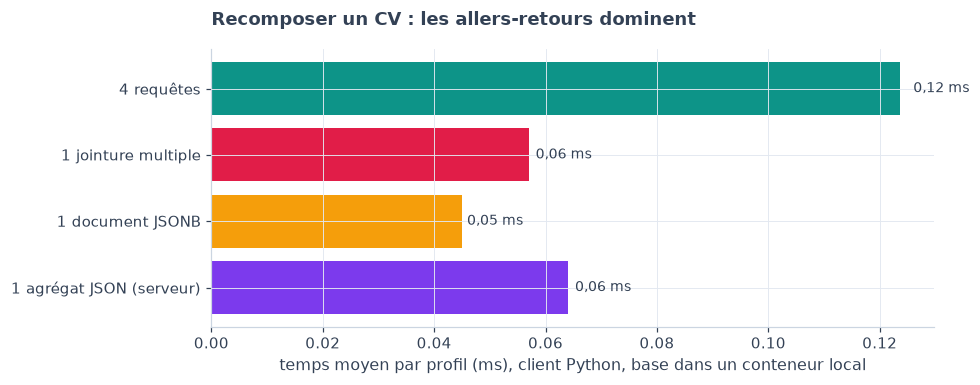

,méthode,requêtes,lignes par profil,ms par profil
0,4 requêtes,4,7.542,0.124
1,1 jointure multiple,1,10.663,0.057
2,1 document JSONB,1,1.000,0.045
3,1 agrégat JSON (serveur),1,1.000,0.064


In [4]:
LECTURES = {
    "4 requêtes": [
        "SELECT * FROM users WHERE id = %(u)s",
        "SELECT job_title, org_id, start_year, end_year FROM positions WHERE user_id = %(u)s",
        "SELECT school_name, start_year, end_year FROM education WHERE user_id = %(u)s",
        "SELECT kind, value FROM contact_info WHERE user_id = %(u)s"],
    "1 jointure multiple": ["""
        SELECT u.*, p.job_title, e.school_name, c.kind, c.value FROM users u
          LEFT JOIN positions p ON p.user_id = u.id LEFT JOIN education e ON e.user_id = u.id
          LEFT JOIN contact_info c ON c.user_id = u.id WHERE u.id = %(u)s"""],
    "1 document JSONB": ["SELECT doc FROM profiles WHERE user_id = %(u)s"],
    "1 agrégat JSON (serveur)": ["""
        SELECT json_build_object('user', to_json(u),
          'positions', (SELECT json_agg(p ORDER BY p.start_year DESC) FROM positions p WHERE p.user_id = u.id),
          'education', (SELECT json_agg(e) FROM education e WHERE e.user_id = u.id),
          'contact_info', (SELECT json_object_agg(kind, value) FROM contact_info c WHERE c.user_id = u.id))
          FROM users u WHERE u.id = %(u)s"""],
}
ids = np.random.default_rng(1).integers(1, 50_001, 2000).tolist()
rows = []
for meth, sqls in LECTURES.items():
    n_rows = 0
    t0 = time.perf_counter()
    for u in ids:
        for s in sqls:
            n_rows += len(q(s, {"u": u}))
    dt = (time.perf_counter() - t0) / len(ids) * 1e3
    rows.append({"méthode": meth, "requêtes": len(sqls), "lignes par profil": n_rows / len(ids), "ms par profil": dt})
lect = pd.DataFrame(rows)
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.barh(lect["méthode"][::-1], lect["ms par profil"][::-1], color=[VIOLET, AMBER, ROSE, TEAL])
for i, v in enumerate(lect["ms par profil"][::-1]):
    ax.text(v * 1.02, i, f"{v:.2f} ms".replace(".", ","), va="center", fontsize=9)
ax.set_xlabel("temps moyen par profil (ms), client Python, base dans un conteneur local")
ax.set_title("Recomposer un CV : les allers-retours dominent")
plt.tight_layout(); plt.show()
lect

Même sur une machine unique (aller-retour local de l'ordre de quelques dizaines de
microsecondes), les quatre requêtes séparées sont les plus lentes : chaque requête paie
l'aller-retour, l'analyse et la planification. Le document JSONB et l'agrégat JSON
n'en paient qu'un. L'agrégat montre la **convergence** des deux modèles : des tables
normalisées à l'écriture, un document à la lecture.

> **À retenir.** Contre une base distante, le nombre de requêtes compte plus que leur
> complexité. Un document, ou un agrégat JSON construit par le serveur, ramène l'arbre
> en un seul aller-retour.

## 3. Indexer des valeurs imbriquées (section *Many-to-One and Many-to-Many Relationships*)

Question plusieurs-à-plusieurs, dans le sens « difficile » : **qui a travaillé pour
l'organisation 520 ?** En relationnel, il faut un index sur `positions(org_id)`. Dans les
documents, l'identifiant est **à l'intérieur** du tableau `positions` ; l'opérateur de
contenance `@>` de JSONB exprime la condition, et un **index GIN** (index inversé sur les
chemins et valeurs du document) peut la servir.

In [5]:
Q_DOC = """SELECT count(*) FROM profiles WHERE doc @> '{"positions": [{"org_id": 520}]}'"""
Q_TAB = "SELECT count(DISTINCT user_id) FROM positions WHERE org_id = 520"
assert q(Q_DOC)[0][0] == q(Q_TAB)[0][0]

def timed(sql, n=20):
    t0 = time.perf_counter()
    for _ in range(n):
        q(sql)
    return (time.perf_counter() - t0) / n * 1e3

def scan_nodes(sql):
    """Les nœuds de parcours du plan (Seq Scan, Index Scan, Bitmap...)."""
    return " ; ".join(l.strip().lstrip("-> ").split("  (")[0] for l in plan(sql).splitlines() if "Scan" in l)

res = [("documents, sans index", scan_nodes(Q_DOC), timed(Q_DOC)),
       ("table, sans index", scan_nodes(Q_TAB), timed(Q_TAB))]
con.execute("CREATE INDEX profiles_gin ON profiles USING gin (doc jsonb_path_ops)")
con.execute("CREATE INDEX positions_org ON positions (org_id)")
con.execute("ANALYZE")
res += [("documents, index GIN", scan_nodes(Q_DOC), timed(Q_DOC)),
        ("table, index B-tree", scan_nodes(Q_TAB), timed(Q_TAB))]
gin = pd.DataFrame(res, columns=["variante", "parcours dans le plan", "ms"])
print(f"{q(Q_DOC)[0][0]} profils ont travaillé pour l'organisation 520 ; "
      f"index GIN : {q('SELECT pg_size_pretty(pg_relation_size(%s))', ('profiles_gin',))[0][0]}")
gin

1306 profils ont travaillé pour l'organisation 520 ; index GIN : 13 MB


,variante,parcours dans le plan,ms
0,"documents, sans index",Seq Scan on profiles,35.978
1,"table, sans index",Seq Scan on positions,4.450
2,"documents, index GIN",Bitmap Heap Scan on profiles ; Bitmap Index Scan on profiles_gin,0.750
3,"table, index B-tree",Bitmap Heap Scan on positions ; Bitmap Index Scan on positions_org,0.311


In [6]:
print(plan(Q_DOC))

Aggregate  (cost=36.76..36.77 rows=1 width=8) (actual rows=1 loops=1)
  Buffers: shared hit=1191
  ->  Bitmap Heap Scan on profiles  (cost=17.12..36.75 rows=5 width=0) (actual rows=1306 loops=1)
        Recheck Cond: (doc @> '{"positions": [{"org_id": 520}]}'::jsonb)
        Heap Blocks: exact=1186
        Buffers: shared hit=1191
        ->  Bitmap Index Scan on profiles_gin  (cost=0.00..17.12 rows=5 width=0) (actual rows=1306 loops=1)
              Index Cond: (doc @> '{"positions": [{"org_id": 520}]}'::jsonb)
              Buffers: shared hit=5
Planning:
  Buffers: shared hit=1


Sans index, PostgreSQL parcourt et décode les 50 000 documents ; avec l'index GIN, il
trouve les documents candidats par un **Bitmap Index Scan**, puis revérifie la condition
sur chacun (*Recheck Cond*). Le gain est du même ordre que celui de l'index B-tree sur la
table normalisée. Les bases relationnelles savent donc, elles aussi, indexer des valeurs
imbriquées dans des documents.

> **À retenir.** Un index GIN sur une colonne JSONB rend interrogeables les valeurs
> imbriquées (opérateur `@>`) : une relation plusieurs-à-plusieurs rangée dans des
> documents s'interroge alors efficacement dans les deux sens.

## 4. Le prix de la localité à l'écriture

Modifier un seul champ d'un document JSONB oblige PostgreSQL à écrire une **nouvelle
version complète** de la valeur (gros documents compressés et déportés dans la table
TOAST compris). Mesurons les octets de journal (WAL) écrits pour changer le titre d'un
profil, selon la taille du document, et comparons avec la mise à jour d'une ligne de
`users`.

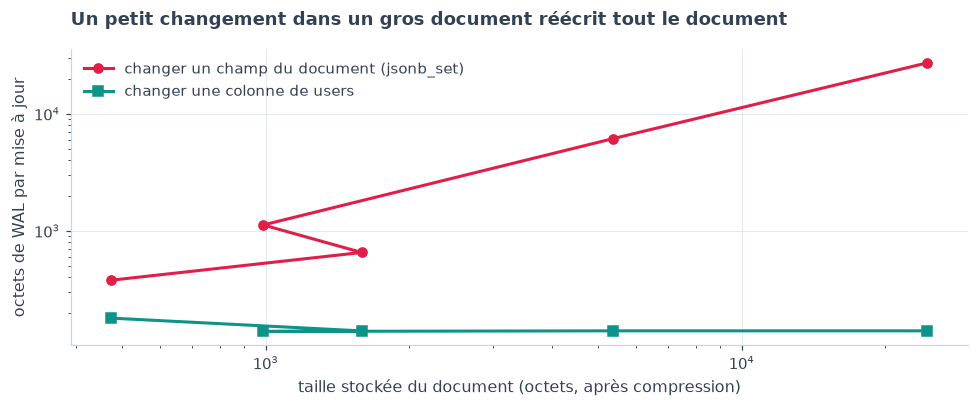

,postes dans le document,taille stockée (octets),WAL par mise à jour du document,WAL par mise à jour d'une ligne
0,1,474.0,379.0,179.0
1,10,1590.0,653.0,140.0
2,100,988.0,1123.0,138.0
3,1000,5372.0,6146.0,140.0
4,5000,24528.0,27268.0,140.0


In [7]:
con.execute("DROP TABLE IF EXISTS bigdocs")
con.execute("CREATE TABLE bigdocs (id int PRIMARY KEY, doc jsonb)")
rows = []
base = profiles[0]
for n_pos in [1, 10, 100, 1000, 5000]:
    big = dict(base, positions=[dict(base["positions"][0], start=1990 + k % 30, job_title=f"poste {k}")
                                for k in range(n_pos)])
    con.execute("TRUNCATE bigdocs")
    with con.cursor() as cur:
        cur.executemany("INSERT INTO bigdocs VALUES (%s, %s)", [(i, Jsonb(big)) for i in range(50)])
    taille = q("SELECT avg(pg_column_size(doc)) FROM bigdocs")[0][0]
    w_doc = wal_bytes(lambda: [q("UPDATE bigdocs SET doc = jsonb_set(doc, '{headline}', %s) WHERE id = %s RETURNING 1",
                                 (Jsonb(f"titre {i}"), i)) for i in range(50)]) / 50
    w_row = wal_bytes(lambda: [q("UPDATE users SET headline = %s WHERE id = %s RETURNING 1", (f"titre {i}", i + 1))
                               for i in range(50)]) / 50
    rows.append({"postes dans le document": n_pos, "taille stockée (octets)": float(taille),
                 "WAL par mise à jour du document": w_doc, "WAL par mise à jour d'une ligne": w_row})
wal = pd.DataFrame(rows)
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.loglog(wal["taille stockée (octets)"], wal["WAL par mise à jour du document"], marker="o", color=ROSE,
          label="changer un champ du document (jsonb_set)")
ax.loglog(wal["taille stockée (octets)"], wal["WAL par mise à jour d'une ligne"], marker="s", color=TEAL,
          label="changer une colonne de users")
ax.set_xlabel("taille stockée du document (octets, après compression)"); ax.set_ylabel("octets de WAL par mise à jour")
ax.set_title("Un petit changement dans un gros document réécrit tout le document")
ax.legend(); plt.tight_layout(); plt.show()
wal.round(0)

Le volume de journal par mise à jour croît comme la taille (compressée) du document,
alors qu'il reste constant pour une ligne. C'est la recommandation du livre vue sur un
vrai moteur : garder des documents assez petits et éviter les petites mises à jour
fréquentes sur de gros documents.

> **À retenir.** Dans PostgreSQL, toute modification d'une valeur JSONB réécrit la valeur
> entière (et la journalise) : le coût d'écriture est proportionnel à la taille du
> document.

## 5. Migrer un schéma (section *Schema flexibility in the document model*)

Le cours 3 a annoncé qu'ajouter une colonne avec une valeur par défaut est rapide, mais
que remplir la colonne réécrit la table. Vérifions-le sur PostgreSQL, avec une table de
500 000 utilisateurs, en mesurant le temps et le journal écrit pour quatre opérations.

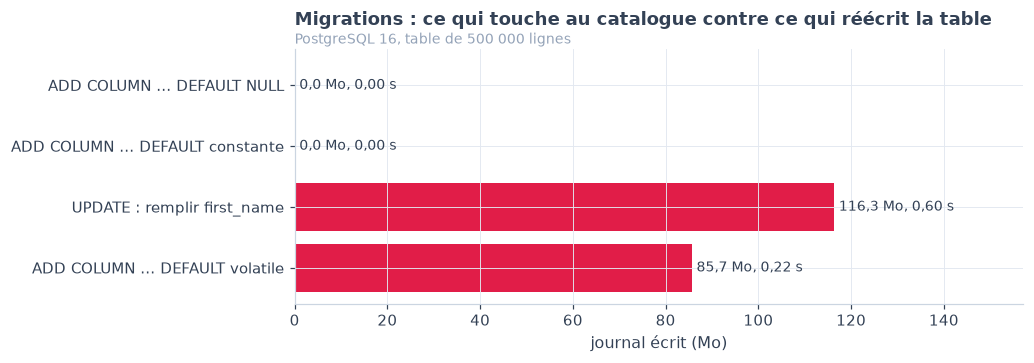

,opération,secondes,WAL (Mo)
0,ADD COLUMN ... DEFAULT NULL,7.754e-04,5.920e-04
1,ADD COLUMN ... DEFAULT constante,4.584e-04,1.544e-03
2,UPDATE : remplir first_name,6.026e-01,1.163e+02
3,ADD COLUMN ... DEFAULT volatile,2.199e-01,8.565e+01


In [8]:
con.execute("DROP TABLE IF EXISTS people")
con.execute("""CREATE TABLE people AS
               SELECT g AS id, 'Prénom' || (g % 997) || ' Nom' || g AS name, repeat('x', 60) AS bio
                 FROM generate_series(1, 500000) g""")
con.execute("VACUUM ANALYZE people")
ops = [
    ("ADD COLUMN ... DEFAULT NULL", "ALTER TABLE people ADD COLUMN first_name text DEFAULT NULL"),
    ("ADD COLUMN ... DEFAULT constante", "ALTER TABLE people ADD COLUMN pays text DEFAULT 'FR'"),
    ("UPDATE : remplir first_name", "UPDATE people SET first_name = split_part(name, ' ', 1)"),
    ("ADD COLUMN ... DEFAULT volatile", "ALTER TABLE people ADD COLUMN cree_le timestamptz DEFAULT clock_timestamp()"),
]
rows = []
for name, sql in ops:
    t0 = time.perf_counter()
    w = wal_bytes(lambda: con.execute(sql))
    rows.append({"opération": name, "secondes": time.perf_counter() - t0, "WAL (Mo)": w / 1e6})
mig = pd.DataFrame(rows)
assert q("SELECT first_name, pays FROM people WHERE id = 5")[0] == ("Prénom5", "FR")
fig, ax = plt.subplots(figsize=(9.5, 3.4))
ax.barh(mig["opération"][::-1], mig["WAL (Mo)"][::-1], color=[ROSE, ROSE, TEAL, TEAL])
for i, (v, s) in enumerate(zip(mig["WAL (Mo)"][::-1], mig["secondes"][::-1])):
    ax.text(v + 1, i, f"{v:.1f} Mo, {s:.2f} s".replace(".", ","), va="center", fontsize=9)
ax.set_xlabel("journal écrit (Mo)"); ax.set_xlim(0, mig["WAL (Mo)"].max() * 1.35)
ax.set_title("Migrations : ce qui touche au catalogue contre ce qui réécrit la table")
subtitle(ax, "PostgreSQL 16, table de 500 000 lignes")
plt.tight_layout(); plt.show()
mig

Ajouter une colonne avec une valeur par défaut `NULL` ou **constante** ne modifie que le
catalogue (PostgreSQL mémorise la valeur par défaut et la fournit à la lecture des
anciennes lignes) : instantané, presque aucun journal. Remplir la colonne par un `UPDATE`
réécrit chaque ligne (nouvelle version MVCC de chaque ligne, des dizaines de mégaoctets
de journal), tout comme une valeur par défaut **volatile**, qui doit être calculée ligne
par ligne. Sur une table de plusieurs téraoctets, c'est la différence entre une
milliseconde et des heures.

> **À retenir.** Dans PostgreSQL, `ADD COLUMN` avec un défaut constant est une
> modification du catalogue ; `UPDATE` de toute la table et défauts volatils réécrivent
> toutes les lignes. Une migration se conçoit en fonction de cette différence.

## 6. Un graphe dans deux tables et `WITH RECURSIVE` (section *Graph Queries in SQL*)

On range le graphe synthétique du cours 4 (lieux emboîtés et 50 000 personnes) dans les
deux tables `vertices` et `edges`, avec les propriétés en JSONB, et on exécute la requête
« nés en Europe, vivant en Amérique du Nord » écrite en SQL récursif.

In [9]:
world = dm.make_world_graph(n_people=50_000, seed=1)
idv = {v: i for i, v in enumerate(world.vertices)}
con.execute("""
DROP TABLE IF EXISTS edges, vertices;
CREATE TABLE vertices (vertex_id int PRIMARY KEY, label text, properties jsonb);
CREATE TABLE edges (edge_id int PRIMARY KEY, tail_vertex int REFERENCES vertices,
                    head_vertex int REFERENCES vertices, label text, properties jsonb);
""")
with con.cursor() as cur:
    with cur.copy("COPY vertices FROM STDIN") as cp:
        for v, (lab, p) in world.vertices.items():
            cp.write_row((idv[v], lab, json.dumps(p, ensure_ascii=False)))
    with cur.copy("COPY edges FROM STDIN") as cp:
        for e, t, h, lab, p in world.edges:
            cp.write_row((e, idv[t], idv[h], lab, json.dumps(p)))
con.execute("""
CREATE INDEX edges_tails ON edges (tail_vertex, label);
CREATE INDEX edges_heads ON edges (head_vertex, label);
CREATE INDEX vertices_name ON vertices (label, (properties ->> 'name'));
""")
con.execute("VACUUM ANALYZE vertices, edges")
SQL_PG = dm.EMIGRANTS_SQL.replace(":born", "%(born)s").replace(":lives", "%(lives)s")
args = {"born": "Europe", "lives": "Amérique du Nord"}
t0 = time.perf_counter(); res_pg = {r[0] for r in q(SQL_PG, args)}; dt = time.perf_counter() - t0
assert res_pg == dm.emigrants_backward(world, "Europe", "Amérique du Nord")
print(f"{len(res_pg)} personnes ; {dt * 1e3:.0f} ms ; identique au parcours en Python")
print("\n".join(l for l in plan(SQL_PG, args).splitlines() if "Recursive" in l or "CTE" in l or "Index" in l)[:1500])

388 personnes ; 12 ms ; identique au parcours en Python
  CTE in_born
    ->  Recursive Union  (cost=0.41..843.69 rows=101 width=4) (actual rows=537 loops=1)
          ->  Index Scan using vertices_name on vertices vertices_1  (cost=0.41..8.43 rows=1 width=4) (actual rows=1 loops=1)
                Index Cond: ((label = 'Location'::text) AND ((properties ->> 'name'::text) = 'Europe'::text))
                ->  Index Scan using edges_heads on edges edges_2  (cost=0.29..8.31 rows=1 width=8) (actual rows=1 loops=537)
                      Index Cond: ((head_vertex = in_born_1.vertex_id) AND (label = 'WITHIN'::text))
  CTE in_lives
    ->  Recursive Union  (cost=0.41..843.69 rows=101 width=4) (actual rows=537 loops=1)
          ->  Index Scan using vertices_name on vertices vertices_2  (cost=0.41..8.43 rows=1 width=4) (actual rows=1 loops=1)
                Index Cond: ((label = 'Location'::text) AND ((properties ->> 'name'::text) = 'Amérique du Nord'::text))
                ->  Index Scan

Le plan montre les deux **Recursive Union** (une par CTE récursive), chacune alimentée par
un parcours d'index sur `edges_heads` : à chaque itération, PostgreSQL ne joint que les
sommets découverts au tour précédent (la « table de travail »), exactement l'évaluation
semi-naïve du cours 5.

Enfin, les **cycles**. Construisons un petit graphe d'amitié avec un cycle et comparons
une récursion qui accumule la profondeur (elle ne s'arrêterait jamais sans borne) avec la
clause `CYCLE` de la norme SQL, disponible depuis PostgreSQL 14, qui marque et coupe les
chemins qui reviennent sur un sommet déjà visité.

In [10]:
con.execute("DROP TABLE IF EXISTS knows")
con.execute("CREATE TABLE knows (a int, b int)")
with con.cursor() as cur:
    cur.executemany("INSERT INTO knows VALUES (%s, %s)", [(0, 1), (1, 2), (2, 3), (3, 1), (2, 4)])
borne = q("""WITH RECURSIVE r(v, d) AS (SELECT 0, 0 UNION SELECT k.b, r.d + 1 FROM knows k JOIN r ON k.a = r.v WHERE r.d < 20)
             SELECT count(*) FROM r""")[0][0]
cyc = q("""WITH RECURSIVE r(v, d) AS (SELECT 0, 0 UNION ALL SELECT k.b, r.d + 1 FROM knows k JOIN r ON k.a = r.v)
           CYCLE v SET est_cycle USING chemin
           SELECT v, d, est_cycle, chemin::text FROM r ORDER BY d""")
print(f"profondeur accumulée, bornée à 20 : {borne} lignes (sans borne : infini)")
pd.DataFrame(cyc, columns=["sommet", "profondeur", "cycle ?", "chemin"])

profondeur accumulée, bornée à 20 : 27 lignes (sans borne : infini)


,sommet,profondeur,cycle ?,chemin
0,0,0,False,{(0)}
1,1,1,False,"{(0),(1)}"
2,2,2,False,"{(0),(1),(2)}"
3,3,3,False,"{(0),(1),(2),(3)}"
4,4,3,False,"{(0),(1),(2),(4)}"
5,1,4,True,"{(0),(1),(2),(3),(1)}"


La clause `CYCLE v SET est_cycle USING chemin` mémorise le chemin parcouru (un tableau de
sommets) et marque la ligne qui revisite un sommet (`1` atteint à nouveau depuis `3`) :
la récursion s'arrête d'elle-même, en gardant la profondeur. C'est la version normalisée de
la détection de cycle écrite à la main dans l'exercice 2.7.

> **À retenir.** Un graphe se range dans deux tables et s'interroge en `WITH RECURSIVE` ;
> PostgreSQL l'évalue par union récursive sur une table de travail (semi-naïf) et sait
> couper les cycles avec la clause `CYCLE`.

## Synthèse

- PostgreSQL est un **hybride relationnel-document** : tables normalisées et colonnes
  JSONB cohabitent, et un agrégat JSON fabrique un document à partir de tables.
- Contre une base distante, le **nombre d'allers-retours** domine : un document (ou un
  agrégat) bat plusieurs requêtes.
- Un **index GIN** rend interrogeables les valeurs imbriquées ; mais toute modification
  d'un document JSONB **réécrit** la valeur entière.
- Ajouter une colonne à défaut constant est instantané ; la remplir réécrit la table.
- `WITH RECURSIVE` interroge un graphe en tables ; la clause `CYCLE` gère les cycles.

Pensez à arrêter les services :
`docker compose -f docker/datamodels/compose.yml -p ddia_datamodels down -v`.